# Figure 2: Diagnose-step graph rendered with Graphviz

Two outputs from one edge list, both laid out by Graphviz `dot`:
* `fig_graph_full.pdf`: every stable link that touches the label or the declared labeling-process variable (GitHub supplement).
* `fig_graph_inset.pdf`: the same graph without the attributes linked only to the label (paper).

Edges are drawn **without arrowheads**: the assumption gate rated the NHANES graph BOUNDED, so the method uses stable adjacencies, not directions (Section 4.1).

**Input:** the edge list in segment 1 is transcribed from the current Figure 2 (NHANES training split, edges in at least 80% of 50 bootstrap resamples). Replace it with the Diagnose notebook's stable-edge output before submission.

In [1]:
import graphviz
print(graphviz.version())

(14, 1, 5)


## 1. Input: stable links that touch the label or the declared variable

In [2]:
CHK, LAB = "CHK", "LAB"   # node IDs (a colon in an ID is read as a port)

check_only = ["usual place for care", "has insurance", "smoker", "income"]
both       = ["doctor visit (past yr)", "education", "Hispanic",
              "age", "BMI", "high cholesterol", "high blood pressure"]
label_only = ["general health", "stroke", "heart disease / attack", "Black", "male"]

flagged = {CHK, "usual place for care", "smoker"}   # variables whose groups were flagged

edges = ([(v, CHK) for v in check_only]
         + [(CHK, v) for v in both] + [(v, LAB) for v in both]
         + [(LAB, v) for v in label_only]
         + [(CHK, LAB)])
print(len(edges), "stable links")

24 stable links


## 2. Build the graph
Left-to-right ranks follow the method's logic: attributes linked only to the declared variable, the declared variable, attributes linked to both, the label, attributes linked only to the label. Graphviz places the nodes and routes the edges within those ranks.

In [3]:
def build(include_label_only=True):
    g = graphviz.Graph("diagnose", engine="dot")
    g.attr(rankdir="LR", nodesep="0.12", ranksep="0.55", splines="true",
           fontname="Helvetica", newrank="true")
    g.attr("node", shape="box", style="rounded,filled", fillcolor="white",
           fontname="Helvetica", fontsize="9", height="0.25", margin="0.06,0.03", penwidth="0.6")
    g.attr("edge", color="gray45", penwidth="0.6")

    def node(sub, v):
        sub.node(v, v, fontname="Helvetica-Bold" if v in flagged else "Helvetica")

    with g.subgraph(name="cluster_valid") as c:
        c.attr(label="O/E check applied", style="filled", color="#e5efe5",
               fontsize="9", fontname="Helvetica-Oblique", labelloc="b")
        for v in check_only: node(c, v)
    with g.subgraph(name="cluster_core") as c:
        c.attr(style="invis")
        c.node(CHK, "cholesterol check (5 yr)\n(declared labeling-process variable)",
               fontname="Helvetica-Bold", penwidth="1.4")
        c.node(LAB, "told: diabetes\n(label)", penwidth="1.4")
    with g.subgraph(name="cluster_filtered") as c:
        c.attr(label="also linked to the label: removed by the label-link filter",
               style="filled", color="#ececec", fontsize="9", fontname="Helvetica-Oblique", labelloc="b")
        for v in both: node(c, v)
    if include_label_only:
        with g.subgraph(name="cluster_labelonly") as c:
            c.attr(label="linked only to the label", style="dashed", color="gray60",
                   fontsize="9", fontname="Helvetica-Oblique", labelloc="b")
            for v in label_only: node(c, v)

    for a, b in edges:
        if not include_label_only and (a in label_only or b in label_only):
            continue
        if {a, b} == {CHK, LAB}:
            g.edge(a, b, color="black", penwidth="1.6", minlen="2", weight="5")
        else:
            g.edge(a, b)
    return g

## 3. Output: full graph (supplement)

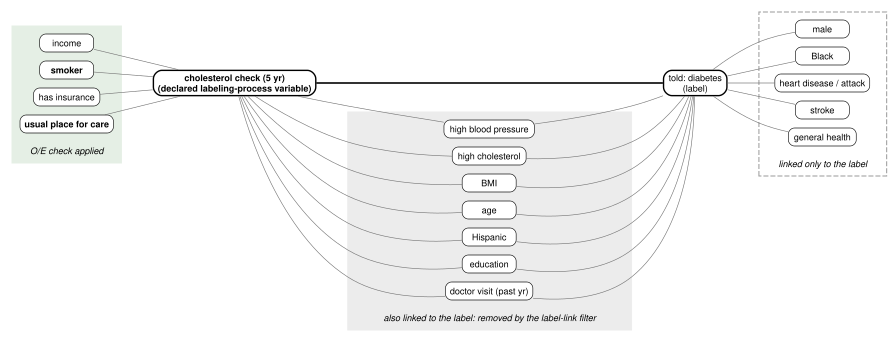

In [4]:
full = build(include_label_only=True)
full.render("fig_graph_full", format="pdf", cleanup=True)
full.render("fig_graph_full", format="png", cleanup=True)
full

## 4. Output: paper inset

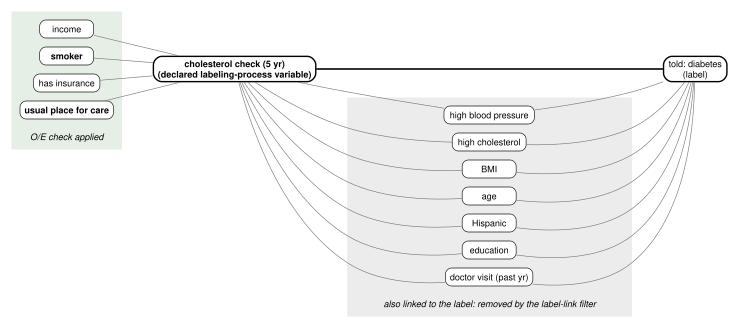

In [5]:
inset = build(include_label_only=False)
inset.render("fig_graph_inset", format="pdf", cleanup=True)
inset.render("fig_graph_inset", format="png", cleanup=True)
inset